SERIES DE VIAS MARÍTIMAS

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
from scipy.stats import boxcox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sktime.forecasting.naive import NaiveForecaster
from prophet import Prophet
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

Funciones a usar:

In [27]:
def estacionariedad_media(datos, alpha):#implementada por Ricardo Rodriguez
    adf = adfuller(datos, regression="c")[1]
    kpss_test = kpss(datos, regression="c", nlags="auto")[1]

    if adf < alpha:
        texto_1 = f'Prueba ADF: Se rechaza la hipótesis nula, ya que el valor p = {adf} < alpha = {alpha}. La serie es estacionaria en media.'
    else:
        texto_1 = f'Prueba ADF: No se rechaza la hipótesis nula, ya que el valor p = {adf} >= alpha = {alpha}. La serie se considera no estacionaria en media.'

    if kpss_test < alpha:
        texto_2 = f'Prueba KPSS: Se rechaza la hipótesis nula, ya que el valor p = {kpss_test} < alpha = {alpha}. La serie no es estacionaria en media.'
    else:
        texto_2 = f'Prueba KPSS: No se rechaza la hipótesis nula, ya que el valor p = {kpss_test} >= alpha = {alpha}. La serie se considera estacionaria en media.'

    print(texto_1)
    print(texto_2)

    if (adf <= alpha and kpss_test <= alpha) or (adf > alpha and kpss_test > alpha):
        print('Las pruebas no coinciden, pero se realizará diferenciación, ya que una muestra la no estacionariedad de la media.')

In [28]:
def estacionariedad_varianza(datos, alpha):#implementada por Ricardo Rodriguez
    arch = het_arch(datos)[1]

    if arch < alpha:
        texto_1 = f'Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = {arch} < alpha = {alpha}. La serie no es estacionaria en varianza. Se hará una transformación.'
    else:
        texto_1 = f'Prueba ARCH: No se rechaza la hipótesis nula, ya que el valor p = {arch} >= alpha = {alpha}. La serie se considera estacionaria en varianza.'

    print(texto_1)

In [29]:
# Función que evalúa las métricas. Implementada por Ricardo Rodriguez
def metricas(y_real, y_pred):
    return {'MAE': mean_absolute_error(y_real, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_real, y_pred))}

In [30]:
df = pd.read_csv("DATOS_LIMPIOS.csv")
df.head()

,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero,Fecha
0,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.0,2009-01-01
1,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.0,2009-01-01
2,Aérea,01 La Aurora,Angola,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA CENTRAL,08 OTROS,Resto del Mundo,Turista,4.0,2009-01-01
3,Aérea,01 La Aurora,Arabia Saudita,OTROS ORIENTE MEDIO,Oriente Medio,ORIENTE MEDIO,08 OTROS,Resto del Mundo,Turista,5.0,2009-01-01
4,Aérea,01 La Aurora,Argelia,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA DEL NORTE,08 OTROS,Resto del Mundo,Turista,1.0,2009-01-01


SERIE DE TIEMPO

In [31]:
df_filtro = df[df["Vía"] == "Marítima"]
df_fecha = df_filtro.groupby("Fecha")["Viajero"].sum().round(0).astype(int)

serie = df_fecha.to_frame("Marítima")
serie = serie.sort_values(by="Fecha", ascending=True)
serie.index = pd.to_datetime(serie.index)
serie.index = serie.index.to_period("M")

ESTIMACIÓN DE LA TENDENCIA DURANTE LA PANDEMIA

In [32]:
inicio = pd.Period('2020-03', freq='M')
fin = pd.Period('2022-12', freq='M')

In [33]:
y_train = serie.loc[serie.index < inicio, 'Marítima']
modelo = NaiveForecaster(strategy='last', sp=12)
modelo.fit(y_train)
fh = range(len(y_train) + 1, len(y_train) + len(pd.period_range(inicio, fin, freq='M')) + 1)
predicciones = modelo.predict(fh=fh)

# Reindexando si no existen
serie = serie.reindex(serie.index.union(pd.period_range(inicio, fin, freq='M')), fill_value=0)
serie.loc[inicio:fin, 'Marítima'] = predicciones.to_numpy()
serie['Marítima'] = serie['Marítima'].round().astype(int)
serie.index = serie.index.to_timestamp()

TRAIN Y TEST

In [34]:
filas, columnas = serie.shape
fil_train = int(filas * 0.7)
train = serie.iloc[:fil_train+1]
test = serie.iloc[fil_train+1:]

In [35]:
serie.head()

,Marítima
2009-01-01,13379
2009-02-01,11674
2009-03-01,11522
2009-04-01,9290
2009-05-01,6517


DESCOMPOSICIÓN DE LA SERIE TEMPORAL

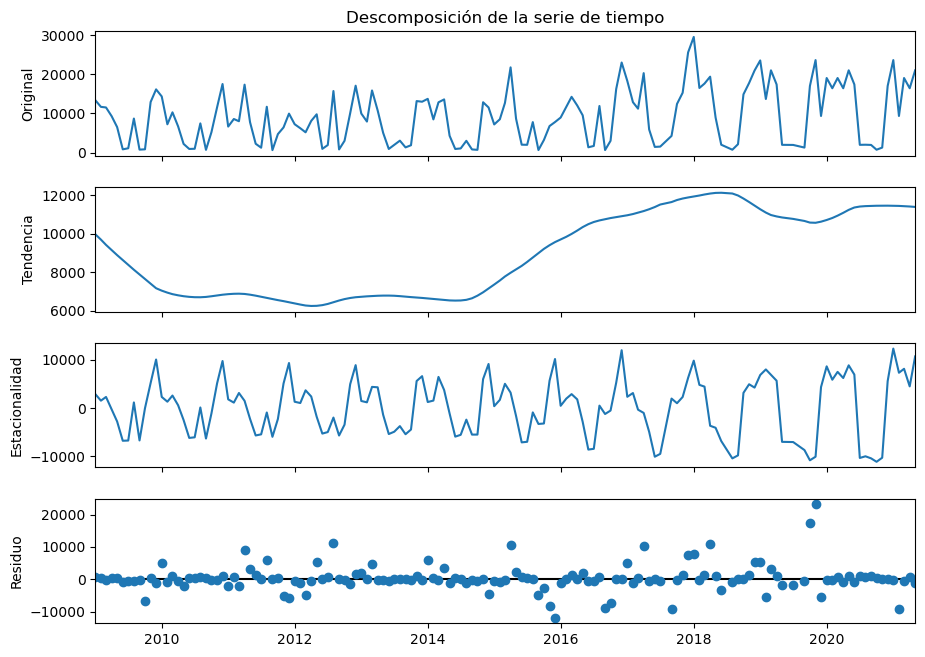

In [36]:
stl = STL(train, period=12, robust=True)

descomposicion = stl.fit()
fig = descomposicion.plot()
fig.set_size_inches(10, 7)
axes = fig.axes
axes[0].set_title('Descomposición de la serie de tiempo')
axes[0].set_ylabel('Original')
axes[1].set_ylabel('Tendencia')
axes[2].set_ylabel('Estacionalidad')
axes[3].set_ylabel('Residuo')
plt.show()

Valor alfa

In [37]:
alfa=0.05

VERIFICACIÓN DE ESTACIONARIEDAD EN MEDIA -- SERIE ORIGINAL

In [38]:
estacionariedad_media(serie, alfa)

Prueba ADF: No se rechaza la hipótesis nula, ya que el valor p = 0.838969111765771 >= alpha = 0.05. La serie se considera no estacionaria en media.
Prueba KPSS: Se rechaza la hipótesis nula, ya que el valor p = 0.03234138755878042 < alpha = 0.05. La serie no es estacionaria en media.


VERIFICACIÓN DE ESTACIONARIEDAD EN MEDIA -- SERIE DIFERENCIADA

In [39]:
estacionariedad_media(train.diff()[1:], alfa)

Prueba ADF: Se rechaza la hipótesis nula, ya que el valor p = 1.9161934783447945e-15 < alpha = 0.05. La serie es estacionaria en media.
Prueba KPSS: No se rechaza la hipótesis nula, ya que el valor p = 0.1 >= alpha = 0.05. La serie se considera estacionaria en media.


C:\Users\aripi\AppData\Local\Temp\ipykernel_28716\1481830582.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_test = kpss(datos, regression="c", nlags="auto")[1]


VERIFICACIÓN DE ESTACIONARIEDAD EN VARIANZA -- SERIE ORIGINAL

In [40]:
estacionariedad_varianza(train, alfa)

Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = 1.256259323891348e-08 < alpha = 0.05. La serie no es estacionaria en varianza. Se hará una transformación.


VERIFICACION DE ESTACIONARIEDAD EN VARIANZA -- SERIE BOX COX

In [41]:
train_box_cox, lambda_optimo = boxcox(train['Marítima'])
estacionariedad_varianza(train_box_cox, alfa)

Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = 1.1909146389681712e-10 < alpha = 0.05. La serie no es estacionaria en varianza. Se hará una transformación.


Dado que aún después de aplicar Box Cox (el cuál se usa para estabilizar este parámetro) la serie sigue siendo no-estacionaria, se intuye que esta característica está arraigada a los datos y no es posible eliminarla de la misma.

TRANSFORMACIONES

In [42]:
trans_train=train

ELECCION DEL PARAMETRO d

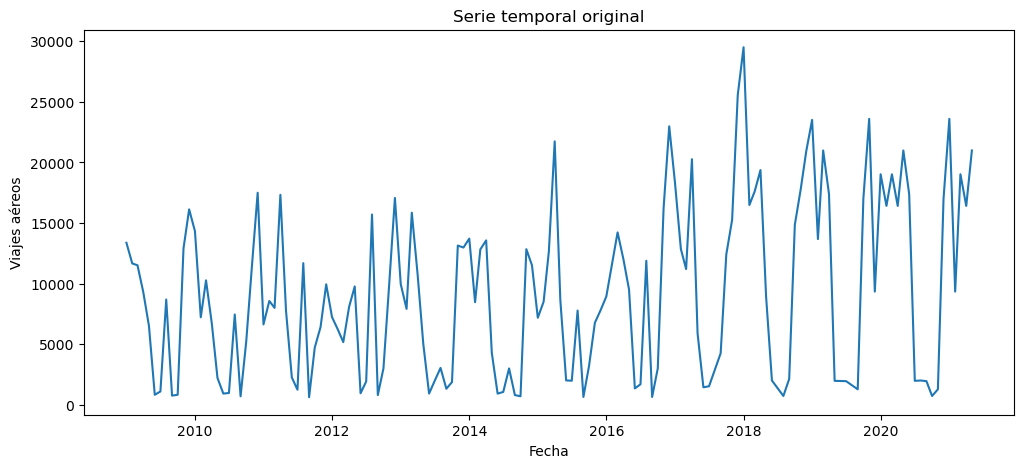

In [43]:
y=train
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.title("Serie temporal original")
plt.xlabel("Fecha")
plt.ylabel("Viajes aéreos")
plt.show()

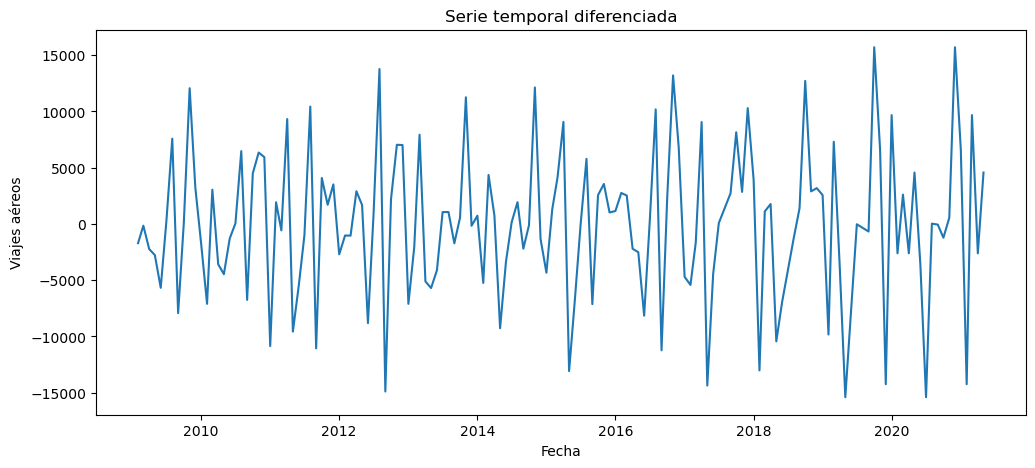

In [44]:
y = train.diff(1).dropna()
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.title("Serie temporal diferenciada")
plt.xlabel("Fecha")
plt.ylabel("Viajes aéreos")
plt.show()

Es posible observar que la media se ha logrado estabilizar.

ELECCIÓN DE LOS PARÁMETROS p & q

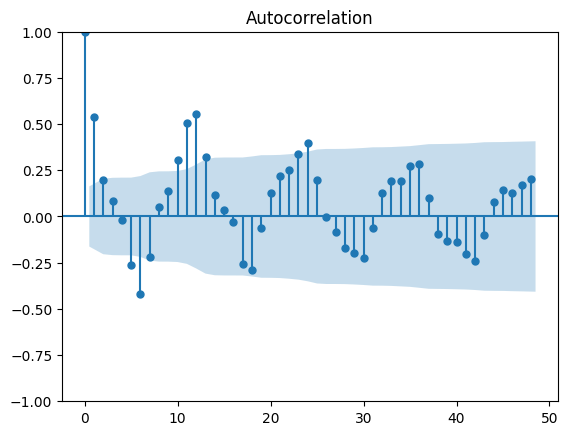

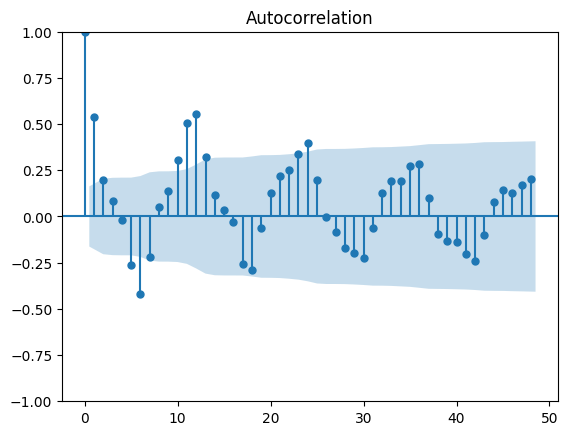

In [20]:
plot_acf(trans_train, lags=48)


Se observa que la autocorrelación llega al umbral en el retraso 13, aunque este lleva una tendencia decreciente durante todo el intervalo considerado.

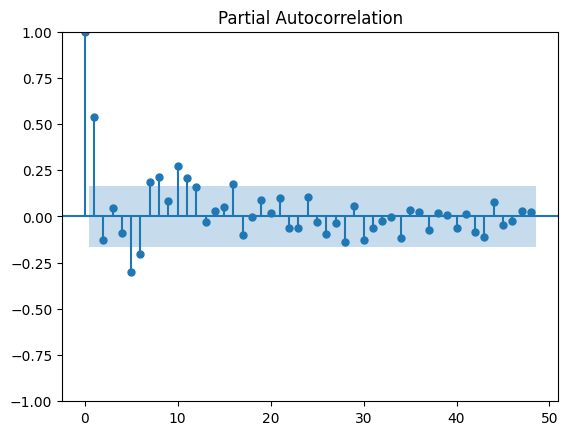

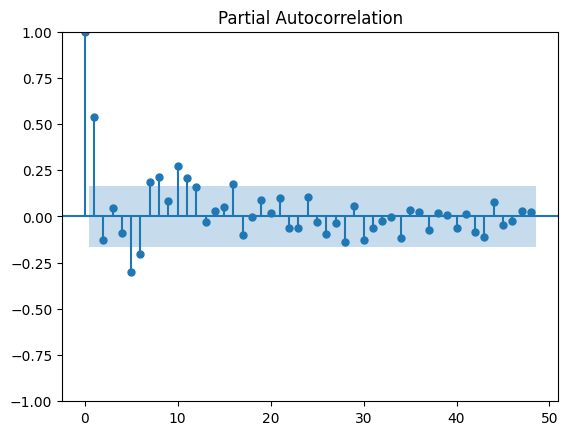

In [21]:
plot_pacf(trans_train, lags=48)

PACF también cae abruptamente en el primer retraso; después logra estabilizarse.

ELECCIÓN DE PARÁMETRO D

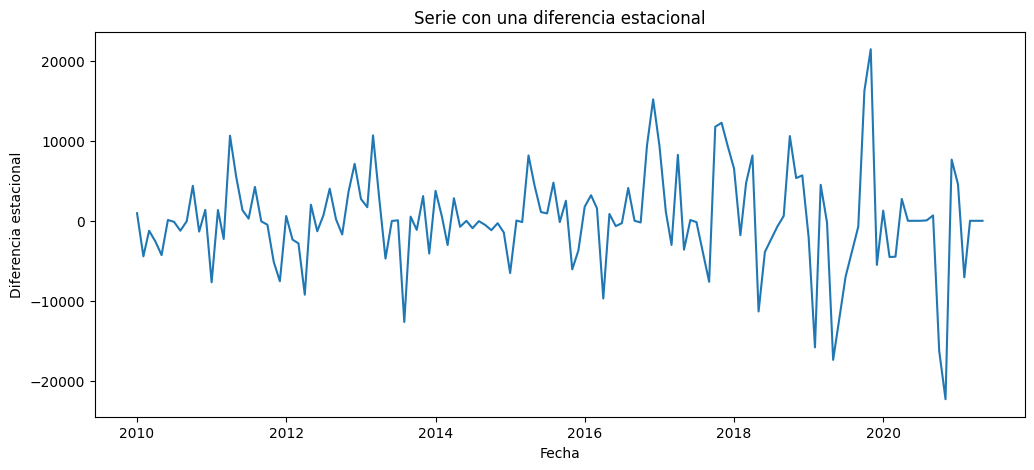

In [22]:
m = 12

y_diff_estacional = train.diff(12)

plt.figure(figsize=(12, 5))
plt.plot(y_diff_estacional)
plt.title("Serie con una diferencia estacional")
plt.xlabel("Fecha")
plt.ylabel("Diferencia estacional")
plt.show()

Se observa cierta estabilidad respecto a la media.

ELECCIÓN DE LOS PARÁMETROS P & Q

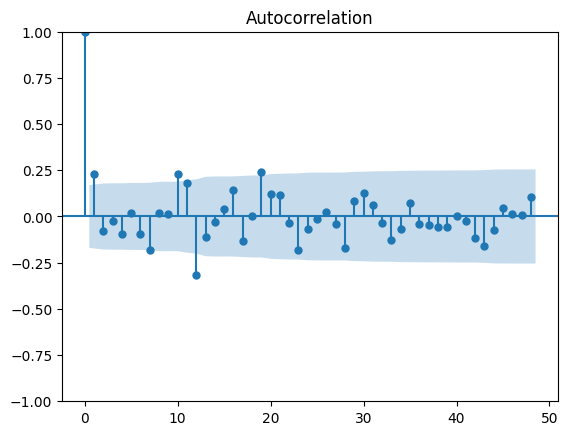

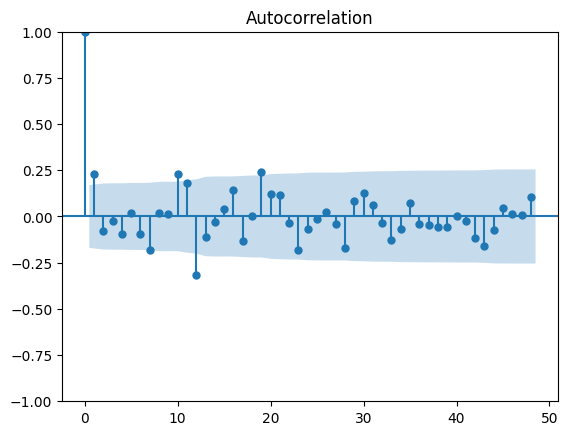

In [23]:
plot_acf(train.diff(12).dropna(), lags=48)

Se observa que ACF cae en el séptimo retraso.

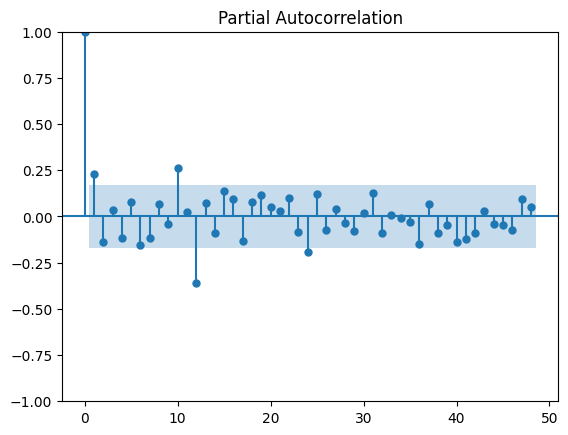

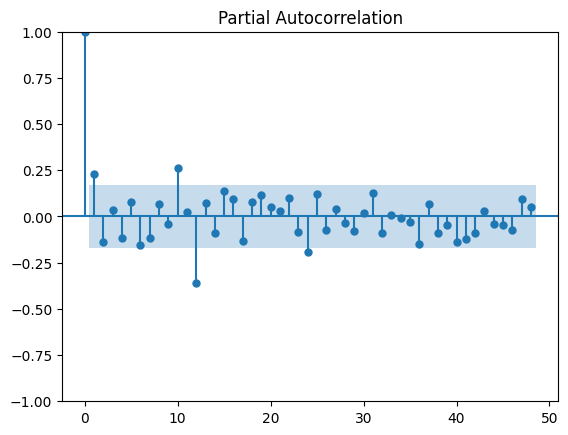

In [24]:
plot_pacf(train.diff(12).dropna(), lags=48)

En este caso, PACF cae en el primer retraso.

ELECCIÓN DE PARÁMETROS

**$d=1$**: Tras la primera diferenciación se llegó a apreciar cierta estacionalidad respecto a la media.

**$p=1$**: La abrupta caida en el primer retraso del PACF hace que llegue al umbral de 0.25.


**$q=1$**: Llega al umbral de 0.25 en el primer retraso en ACF


**$D=1$**: Dado que se ha estabilizado tras la primera diferenciación.


**$P=0$**: Se observa que el retraso 1 no es significativo en el PACF.


**$Q=0$**: Se observa que el retraso 1 no es significativo en el ACF.

ENTRENAMIENTO DE MODELOS **SARIMA**

In [45]:
modelo_1 = SARIMAX(trans_train, order=(1, 1, 1), seasonal_order=(0, 1, 0, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_1 = modelo_1.fit(maxiter=500, disp=False)

C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [46]:
modelo_2 = SARIMAX(trans_train, order=(2, 1, 0), seasonal_order=(0, 1, 0, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_2 = modelo_2.fit(maxiter=500, disp=False)

C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [47]:
modelo_3 = SARIMAX(trans_train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_3 = modelo_3.fit(maxiter=500, disp=False)

C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


COMPARACIÓN DE MODELOS

In [48]:
modelos = {"SARIMA 1": sarima_1, "SARIMA 2": sarima_2, "SARIMA 3": sarima_3}

resultados = []

for nombre, modelo in modelos.items():
    residuos = modelo.resid.dropna()

    ljung_box = acorr_ljungbox(residuos, lags=[12], return_df=True)
    resultados.append({"Modelo": nombre, "AIC": modelo.aic, "BIC": modelo.bic, "Media residuos": residuos.mean(), 
                       "Ljung-Box p-value": ljung_box["lb_pvalue"].iloc[0]})

comparacion = pd.DataFrame(resultados).sort_values(by=["AIC", "BIC"])

print(comparacion)

     Modelo          AIC          BIC  Media residuos  Ljung-Box p-value
2  SARIMA 3  2387.575613  2401.429037     -149.771743       5.221911e-03
0  SARIMA 1  2646.494042  2655.096645     -815.519174       3.364488e-05
1  SARIMA 2  2670.484001  2679.086605        7.651617       6.067386e-09


Se procede a la elección del modelo SARIMA 3 ya que tanto AIC como BIC son menores que en los otros dos modelos. Se observa que todos los valores p son menores a 0.05, razón por la que cumplen con la independencia de los residuos.

OTROS MODELOS

In [49]:
# Período de predicción.
periodo_estacional = 12
predicciones = {}
# Métricas de los modelos SARIMA
modelos_sarima = {
    'SARIMA 1': sarima_1,
    'SARIMA 2': sarima_2,
    'SARIMA 3': sarima_3
}

for nombre, modelo in modelos_sarima.items():
    predicciones[nombre] = modelo.forecast(steps=len(test))

C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning 

In [51]:
# Prophet
prophet_train = pd.DataFrame({'ds': trans_train.index,
                              'y': trans_train['Marítima']})

modelo_prophet = Prophet()
modelo_prophet.fit(prophet_train)
futuro = pd.DataFrame({'ds': test.index})
predicciones['Prophet'] = modelo_prophet.predict(futuro)['yhat'].values

13:11:24 - cmdstanpy - INFO - Chain [1] start processing
13:11:24 - cmdstanpy - INFO - Chain [1] done processing


In [52]:
# Holt-Winters
modelo_hw = ExponentialSmoothing(trans_train, trend="add", seasonal="add", seasonal_periods=periodo_estacional).fit()
predicciones["Holt-Winters"] = modelo_hw.forecast(len(test))

C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [53]:
# Suavizamiento exponencial simple
modelo_ses = SimpleExpSmoothing(trans_train).fit(optimized=True)
predicciones["Suavizamiento exponencial"] = modelo_ses.forecast(len(test))

C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [54]:
# Seasonal Naive
predicciones["Seasonal Naive"] = np.resize(trans_train.iloc[-periodo_estacional:].values, len(test))

In [55]:
# Comparación
resultados = []

for nombre, prediccion in predicciones.items():
    valores = metricas(test.values, np.asarray(prediccion))

    resultados.append({
        "Modelo": nombre,
        "MAE": valores["MAE"],
        "RMSE": valores["RMSE"],
        "AIC": modelos_sarima[nombre].aic
        if nombre in modelos_sarima else np.nan,
        "BIC": modelos_sarima[nombre].bic
        if nombre in modelos_sarima else np.nan
    })

comparacion = pd.DataFrame(resultados).sort_values("RMSE")

print(comparacion)
print("\nMejor modelo:", comparacion.iloc[0]["Modelo"])

                      Modelo           MAE          RMSE          AIC  \
1                   SARIMA 2   7836.819672  11721.675914  2670.484001   
6             Seasonal Naive   7836.819672  11721.675914          NaN   
4               Holt-Winters  10517.337805  12330.196127          NaN   
0                   SARIMA 1   8759.231125  12491.256678  2646.494042   
3                    Prophet  12082.318115  13496.057291          NaN   
2                   SARIMA 3  11697.642979  13612.435837  2387.575613   
5  Suavizamiento exponencial  16728.233868  17666.148285          NaN   

           BIC  
1  2679.086605  
6          NaN  
4          NaN  
0  2655.096645  
3          NaN  
2  2401.429037  
5          NaN  

Mejor modelo: SARIMA 2


ELECCION DEL MEJOR MODELO

In [56]:
# Predicción del mejor modelo
indice = 0
mejor_modelo_nombre = comparacion.iloc[indice]["Modelo"]
print('Se selecciona el modelo:', mejor_modelo_nombre)
mejor_modelo = sarima_1

Se selecciona el modelo: SARIMA 2


GRÁFICA DE PREDICCIÓN

C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\aripi\anaconda3\envs\DataMining\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


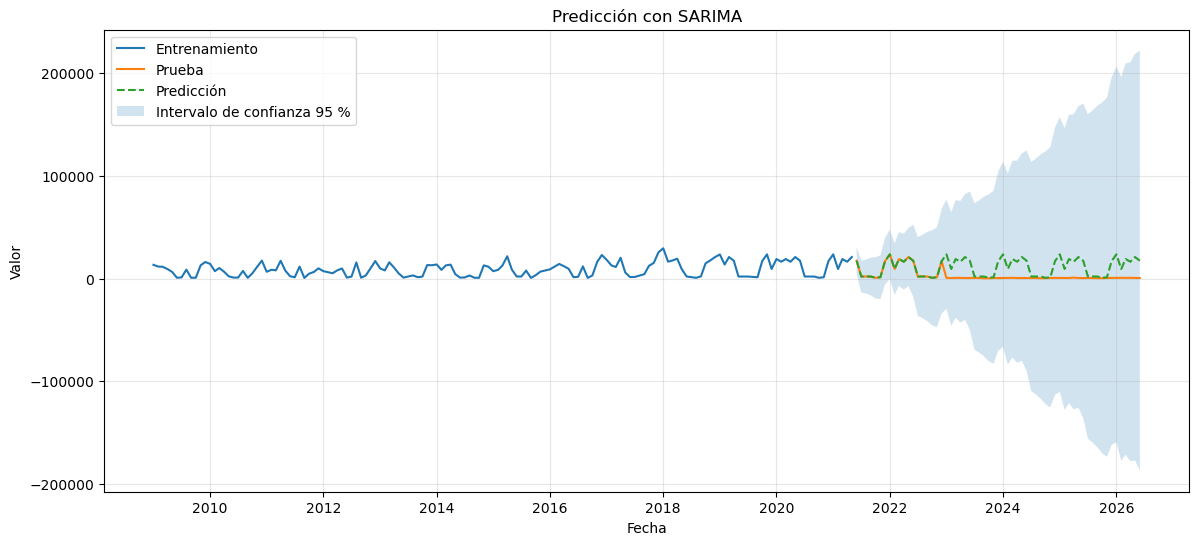

In [57]:
# Predicción e intervalos de confianza
pronostico_sarima = sarima_2.get_forecast(steps=len(test))
prediccion_sarima = pronostico_sarima.predicted_mean
intervalos = pronostico_sarima.conf_int(alpha=0.05)

limite_inferior = intervalos.iloc[:, 0]
limite_superior = intervalos.iloc[:, 1]

# Ajustar el índice al conjunto de prueba
prediccion_sarima.index = test.index
limite_inferior.index = test.index
limite_superior.index = test.index

# Gráfica
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, label="Entrenamiento")
plt.plot(test.index, test, label="Prueba")
plt.plot(test.index, prediccion_sarima, linestyle="--", label="Predicción")
plt.fill_between(test.index, limite_inferior, limite_superior, alpha=0.2, label="Intervalo de confianza 95 %")
plt.title("Predicción con SARIMA")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

El modelo SARIMA 2, ha logrado seguir la tendencia durante el 2022 y hasta el 2023, después del cuál los datos cambian su patrón anterior; lo que provoca que el modelo no pueda predecirlo correctamente.